### 1. Importing Required Libraries

- **Pandas and NumPy:** Data manipulation and numerical operations.
- **Matplotlib and Seaborn:** Data visualization.
- **StandardScaler:** Scales eligible session features without retaining a full scaled copy.
- **AgglomerativeClustering:** Fits a Ward-linkage hierarchy on a representative sample.
- **Clustering metrics:** Compare candidate cluster counts and evaluate the fitted sample.
- **PCA and t-SNE:** Project labeled sessions for visualization.
- **Linkage and Dendrogram:** Visualize the hierarchy on a manageable subset.
- **RANDOM_STATE = 42:** Makes all sampling reproducible.

In [1]:
# Data manipulation
import gc
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import StandardScaler

# Hierarchical clustering
from sklearn.cluster import AgglomerativeClustering

# Clustering evaluation and assignment
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Dimensionality reduction / visualization
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Hierarchical clustering visualization
from scipy.cluster.hierarchy import dendrogram, linkage

# Reproducibility
RANDOM_STATE = 42

print("All modules imported successfully.")

All modules imported successfully.


In [2]:
df = pd.read_csv(
    "../data/raw/2019-Oct.csv"
)

### 2. Basic Data Inspection

- **Shape and Columns:** Checks the dataset size and column names.
- **First 5 Rows:** Displays sample records.
- **Data Types:** Identifies the type of each column.
- **Missing Values and Duplicates:** Checks data quality.
- **Statistical Summary:** Summarizes numerical features.
- **Event Distribution:** Counts occurrences of each event type.
- **Unique Values:** Counts distinct users, sessions, products, categories, and brands.
- **Price Summary:** Examines the distribution of product prices.
- **Event Time Conversion:** Converts `event_time` to datetime format, handling invalid values as missing.

In [3]:

# Basic Inspection
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

# Data Types
print("\nData Types:")
print(df.dtypes)

# Missing Values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate Rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Statistical Summary
print("\nNumerical Summary:")
display(df.describe())

# Event Distribution
print("\nEvent Types:")
print(df["event_type"].value_counts())

# Unique Values
print("\nUnique Users:", df["user_id"].nunique())
print("Unique Sessions:", df["user_session"].nunique())
print("Unique Products:", df["product_id"].nunique())
print("Unique Categories:", df["category_id"].nunique())
print("Unique Brands:", df["brand"].nunique())

# Price Check
print("\nPrice Summary:")
display(df["price"].describe())

# Convert Event Time
df["event_time"] = pd.to_datetime(df["event_time"], errors="coerce")

print("\nEvent Time Type:", df["event_time"].dtype)

Shape: (42448764, 9)

Columns:
['event_time', 'event_type', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id', 'user_session']

First 5 Rows:


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-10-01 00:00:00 UTC,view,44600062,2103807459595387724,NaN,shiseido,35.79,541312140,72d76fde-8bb3-4e00-8c23-a032dfed738c
1,2019-10-01 00:00:00 UTC,view,3900821,2053013552326770905,appliances.environment.water_heater,aqua,33.20,554748717,9333dfbd-b87a-4708-9857-6336556b0fcc
2,2019-10-01 00:00:01 UTC,view,17200506,2053013559792632471,furniture.living_room.sofa,NaN,543.10,519107250,566511c2-e2e3-422b-b695-cf8e6e792ca8
3,2019-10-01 00:00:01 UTC,view,1307067,2053013558920217191,computers.notebook,lenovo,251.74,550050854,7c90fc70-0e80-4590-96f3-13c02c18c713
4,2019-10-01 00:00:04 UTC,view,1004237,2053013555631882655,electronics.smartphone,apple,1081.98,535871217,c6bd7419-2748-4c56-95b4-8cec9ff8b80d



Data Types:
event_time        object
event_type        object
product_id         int64
category_id        int64
category_code     object
brand             object
price            float64
user_id            int64
user_session      object
dtype: object

Missing Values:
event_time              0
event_type              0
product_id              0
category_id             0
category_code    13515609
brand             6117080
price                   0
user_id                 0
user_session            2
dtype: int64

Duplicate Rows: 30220

Numerical Summary:


,product_id,category_id,price,user_id
count,4.244876e+07,4.244876e+07,4.244876e+07,4.244876e+07
mean,1.054993e+07,2.057404e+18,2.903237e+02,5.335371e+08
std,1.188191e+07,1.843926e+16,3.582692e+02,1.852374e+07
min,1.000978e+06,2.053014e+18,0.000000e+00,3.386938e+07
25%,1.005157e+06,2.053014e+18,6.598000e+01,5.159043e+08
50%,5.000470e+06,2.053014e+18,1.629300e+02,5.296965e+08
75%,1.600030e+07,2.053014e+18,3.585700e+02,5.515788e+08
max,6.050001e+07,2.175420e+18,2.574070e+03,5.662809e+08



Event Types:
event_type
view        40779399
cart          926516
purchase      742849
Name: count, dtype: int64

Unique Users: 3022290
Unique Sessions: 9244421
Unique Products: 166794
Unique Categories: 624
Unique Brands: 3444

Price Summary:


count    4.244876e+07
mean     2.903237e+02
std      3.582692e+02
min      0.000000e+00
25%      6.598000e+01
50%      1.629300e+02
75%      3.585700e+02
max      2.574070e+03
Name: price, dtype: float64


Event Time Type: datetime64[ns, UTC]


### 3.1 Event Type Distribution

**Purpose:** Visualizes the frequency of each event type.

**Observations:**
- Identifies the most and least frequent user interactions.
- Reveals how user activity is distributed across event types.

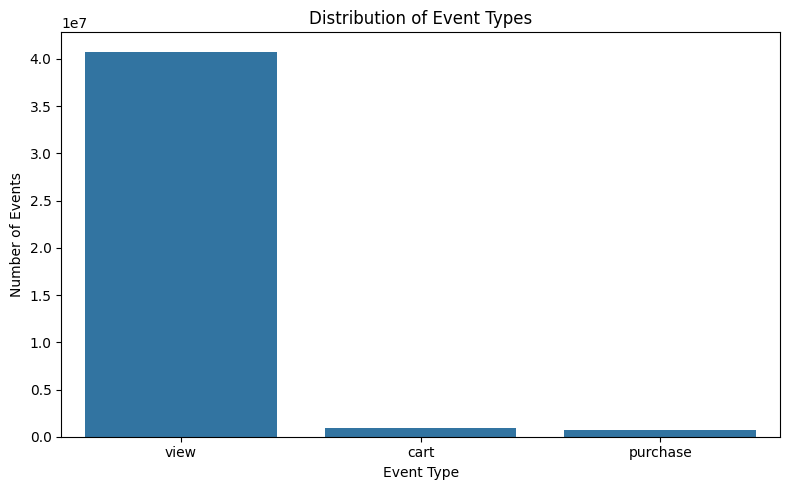

In [4]:
event_counts = df["event_type"].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(x=event_counts.index, y=event_counts.values)

plt.title("Distribution of Event Types")
plt.xlabel("Event Type")
plt.ylabel("Number of Events")
plt.tight_layout()
plt.show()

### 3.2 Missing Value Analysis

**Purpose:** Visualizes raw event-level missing values.

**Observed in the saved run:** `category_code` and `brand` have many missing values, while `user_session` has only two missing rows. Category code and brand are not used as clustering features; rows without a session identifier are removed before session aggregation. Missingness is handled according to feature meaning rather than imputed globally.

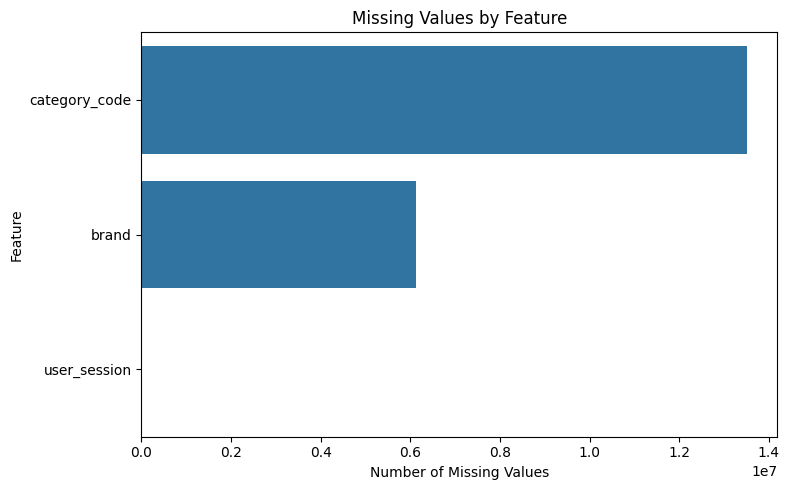

In [5]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if not missing.empty:
    plt.figure(figsize=(8, 5))
    sns.barplot(x=missing.values, y=missing.index)

    plt.title("Missing Values by Feature")
    plt.xlabel("Number of Missing Values")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

### 3.3 Product Price Distribution

**Purpose:** Examines product prices using a histogram and KDE curve.

**Observations:**
- Shows the spread and concentration of product prices.
- Helps identify skewness and potential outliers.
- Uses a sample of up to 500,000 records for visualization.

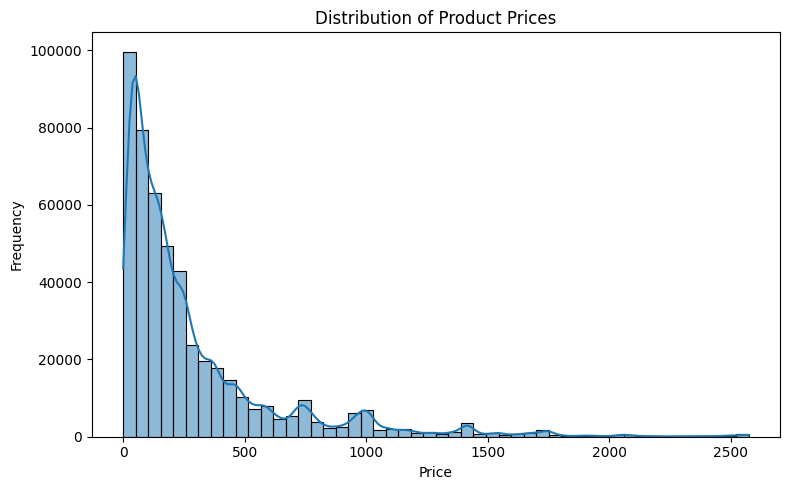

In [6]:
price_sample = df["price"].dropna().sample(
    n=min(500000, df["price"].notna().sum()),
    random_state=RANDOM_STATE
)

plt.figure(figsize=(8, 5))
sns.histplot(price_sample, bins=50, kde=True)

plt.title("Distribution of Product Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### 3.4 Product, Category and Brand Diversity

**Purpose:** Counts unique products, categories, and brands.

**Observations:**
- Shows the diversity of products and brands.
- Helps understand the variety of items associated with user interactions.

In [7]:
print("Unique Products:", df["product_id"].nunique())
print("Unique Categories:", df["category_id"].nunique())
print("Unique Brands:", df["brand"].nunique())

Unique Products: 166794
Unique Categories: 624
Unique Brands: 3444


### 3.5 Top 15 Categories by Events

**Purpose:** Displays the 15 categories with the highest number of events.

**Observations:**
- Identifies categories receiving the most user interactions.
- Highlights popular categories in the dataset.

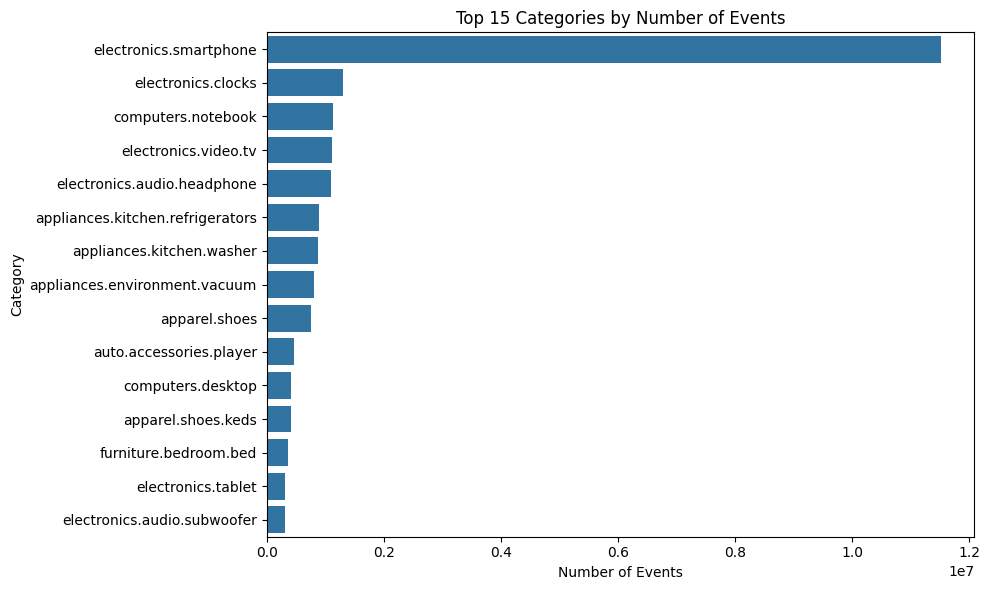

In [8]:
top_categories = df["category_code"].value_counts().head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_categories.values, y=top_categories.index)

plt.title("Top 15 Categories by Number of Events")
plt.xlabel("Number of Events")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

### 3.6 Top 15 Brands by Events

**Purpose:** Displays the 15 brands associated with the highest number of events.

**Observations:**
- Identifies brands with the most recorded user interactions.
- Helps compare brand popularity based on event counts.

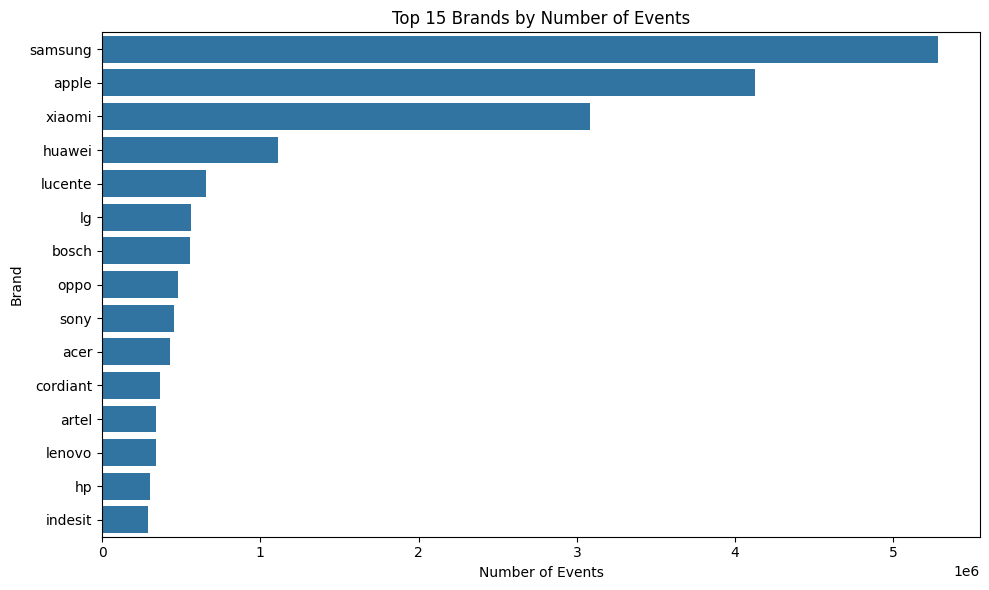

In [9]:
top_brands = df["brand"].value_counts().head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_brands.values, y=top_brands.index)

plt.title("Top 15 Brands by Number of Events")
plt.xlabel("Number of Events")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

### Observations
- **Event distribution:** Views dominate the saved run (40,779,399 views versus 926,516 cart and 742,849 purchase events), so event-type-specific aggregation is essential.
- **Missing values:** The raw data has extensive missing `category_code` and `brand` values; neither is used in session clustering. Only two events lack a session key in the saved inspection.
- **Price distribution:** The event-level histogram is strongly right-skewed and includes zero prices. Zero values are retained as observed prices, not treated as missing.
- **Product/category/brand plots:** These describe event popularity, not session clusters; the clustering features are derived independently at the session level.

### 4.1 Data Cleaning

**Purpose:** Removes duplicate event rows and rows without a session identifier, then keeps only the fields required for session-level analysis.

**Data-handling notes:** The saved inspection found 30,220 duplicate rows and two rows without `user_session`. The raw event table is released after creating the reduced working table to avoid retaining two 42-million-row DataFrames. The aggregated session table still retains all sessions, including sessions that will later be ineligible for clustering.

In [10]:
df_clean = df.drop_duplicates().dropna(subset=["user_session"])

print("Rows after removing full-row duplicates and missing sessions:", len(df_clean))
print("Duplicate rows remaining:", df_clean.duplicated().sum())
print("Missing sessions remaining:", df_clean["user_session"].isna().sum())

# Keep only columns required by session feature engineering.
df_clean = df_clean.loc[
    :, ["event_time", "event_type", "product_id", "category_id", "price", "user_session"]
]
del df
gc.collect()
print("Working columns:", df_clean.columns.tolist())

Rows after removing full-row duplicates and missing sessions: 42418542
Duplicate rows remaining: 0
Missing sessions remaining: 0
Working columns: ['event_time', 'event_type', 'product_id', 'category_id', 'price', 'user_session']


### 4.2 Price and Event-Value Checks

**Purpose:** Reports missing, non-finite, zero, and negative prices before feature engineering.

**Observed in the saved run:** 68,670 prices are exactly zero and no negative prices were reported. Zero is retained as a recorded value rather than treated as missing; only missing/non-finite feature values are excluded from clustering. Price checks do not filter out events.

In [11]:
price_values = df_clean["price"].to_numpy(dtype=np.float64, copy=False)

print("Missing prices:", int(df_clean["price"].isna().sum()))
print("Non-finite prices:", int((~np.isfinite(price_values)).sum()))
print("Zero-price events:", int(df_clean["price"].eq(0).sum()))
print("Negative-price events:", int(df_clean["price"].lt(0).sum()))
print("Zero-price events by event type:")
display(
    df_clean.loc[df_clean["price"].eq(0)]
    .groupby("event_type", observed=True)
    .size()
    .rename("zero_price_events")
    .to_frame()
)

Missing prices: 0
Non-finite prices: 0
Zero-price events: 68670
Negative-price events: 0
Zero-price events by event type:


,zero_price_events
event_type,
cart,149
view,68521


### 4.3 Timestamp and Event-Type Preparation

**Purpose:** Parses event timestamps as UTC and reports unparseable values. Event types are stored categorically to reduce memory use; event-type-specific features are aggregated directly from the appropriate rows rather than relying on ambiguous helper columns.

In [12]:
df_clean["event_time"] = pd.to_datetime(
    df_clean["event_time"],
    errors="coerce",
    utc=True
)
df_clean["event_type"] = df_clean["event_type"].astype("category")

invalid_timestamp_count = int(df_clean["event_time"].isna().sum())
print("Unparseable event timestamps:", invalid_timestamp_count)
print("Event types:")
print(df_clean["event_type"].value_counts(dropna=False))

Unparseable event timestamps: 0
Event types:
event_type
view        40777328
cart          898441
purchase      742773
Name: count, dtype: int64


### 4.4 Session-Level Feature Engineering

**Purpose:** Builds one row per session, with features scoped to the event type they describe.

- `unique_products_viewed`, `unique_categories_viewed`, `total_views`, `avg_price_viewed`, and `max_price_viewed` use **view events only**.
- `cart_additions` and `unique_products_carted` use **cart events only**.
- Session start/end use all parseable event timestamps.
- Sessions without views retain zero view counts and missing viewed-price statistics; missing viewed prices are not imputed as zero.

The aggregation preserves the full session population so non-view sessions remain available for non-clustering analyses.

In [13]:
print("Aggregating session times...")
session_times = (
    df_clean
    .groupby("user_session", sort=False, observed=True)["event_time"]
    .agg(session_start="min", session_end="max")
)

print("Aggregating view-only features...")
view_events = df_clean.loc[
    df_clean["event_type"].eq("view"),
    ["user_session", "product_id", "category_id", "price"]
]
view_features = (
    view_events
    .groupby("user_session", sort=False, observed=True)
    .agg(
        unique_products_viewed=("product_id", "nunique"),
        unique_categories_viewed=("category_id", "nunique"),
        total_views=("product_id", "size"),
        avg_price_viewed=("price", "mean"),
        max_price_viewed=("price", "max")
    )
)
del view_events
gc.collect()

print("Aggregating cart-only features...")
cart_events = df_clean.loc[
    df_clean["event_type"].eq("cart"),
    ["user_session", "product_id"]
]
cart_features = (
    cart_events
    .groupby("user_session", sort=False, observed=True)
    .agg(
        cart_additions=("product_id", "size"),
        unique_products_carted=("product_id", "nunique")
    )
)
del cart_events
gc.collect()

session_features = (
    session_times
    .join(view_features, how="left")
    .join(cart_features, how="left")
    .reset_index()
)

print("Session-level shape:", session_features.shape)
display(session_features.head())

Aggregating session times...
Aggregating view-only features...
Aggregating cart-only features...
Session-level shape: (9244421, 10)


,user_session,session_start,session_end,unique_products_viewed,unique_categories_viewed,total_views,avg_price_viewed,max_price_viewed,cart_additions,unique_products_carted
0,72d76fde-8bb3-4e00-8c23-a032dfed738c,2019-10-01 00:00:00+00:00,2019-10-01 00:00:15+00:00,1.0,1.0,2.0,35.790000,35.79,NaN,NaN
1,9333dfbd-b87a-4708-9857-6336556b0fcc,2019-10-01 00:00:00+00:00,2019-10-01 00:00:00+00:00,1.0,1.0,1.0,33.200000,33.20,NaN,NaN
2,566511c2-e2e3-422b-b695-cf8e6e792ca8,2019-10-01 00:00:01+00:00,2019-10-01 00:07:03+00:00,9.0,2.0,12.0,578.625000,882.88,NaN,NaN
3,7c90fc70-0e80-4590-96f3-13c02c18c713,2019-10-01 00:00:01+00:00,2019-10-01 00:03:17+00:00,5.0,1.0,7.0,582.668571,1512.78,NaN,NaN
4,c6bd7419-2748-4c56-95b4-8cec9ff8b80d,2019-10-01 00:00:04+00:00,2019-10-01 00:00:43+00:00,2.0,1.0,3.0,1525.853333,1747.79,NaN,NaN


### 4.5 Session Duration Calculation

**Purpose:** Calculates elapsed minutes between the earliest and latest parseable event timestamps in each session. A zero duration is valid when timestamps coincide. If a session has no parseable timestamps, its duration remains missing and that session is excluded from clustering rather than assigned an artificial duration.

In [14]:
session_features["session_duration_minutes"] = (
    session_features["session_end"] - session_features["session_start"]
).dt.total_seconds() / 60

duration = session_features["session_duration_minutes"]
print("Sessions with missing duration:", int(duration.isna().sum()))
print("Sessions with non-finite duration:", int((~np.isfinite(duration.dropna())).sum()))
print("Sessions with negative duration:", int(duration.lt(0).sum()))
display(
    session_features[
        ["user_session", "session_start", "session_end", "session_duration_minutes"]
    ].head()
)

Sessions with missing duration: 0
Sessions with non-finite duration: 0
Sessions with negative duration: 0


,user_session,session_start,session_end,session_duration_minutes
0,72d76fde-8bb3-4e00-8c23-a032dfed738c,2019-10-01 00:00:00+00:00,2019-10-01 00:00:15+00:00,0.250000
1,9333dfbd-b87a-4708-9857-6336556b0fcc,2019-10-01 00:00:00+00:00,2019-10-01 00:00:00+00:00,0.000000
2,566511c2-e2e3-422b-b695-cf8e6e792ca8,2019-10-01 00:00:01+00:00,2019-10-01 00:07:03+00:00,7.033333
3,7c90fc70-0e80-4590-96f3-13c02c18c713,2019-10-01 00:00:01+00:00,2019-10-01 00:03:17+00:00,3.266667
4,c6bd7419-2748-4c56-95b4-8cec9ff8b80d,2019-10-01 00:00:04+00:00,2019-10-01 00:00:43+00:00,0.650000


### 4.6 Purchase Information

**Purpose:** Calculates the number of purchase events and their total recorded price for each session.

**Observations:**
- `purchase_count` indicates the number of purchase events in a session.
- `purchase_value` represents the sum of prices recorded for purchase events.
- Sessions without purchase events are excluded here and handled in the next step.

In [15]:
print("Creating purchase information...")

purchase_info = (
    df_clean[df_clean["event_type"] == "purchase"]
    .groupby("user_session", sort=False)
    .agg(
        purchase_count=("event_type", "size"),
        purchase_value=("price", "sum")
    )
    .reset_index()
)

display(purchase_info.head())

Creating purchase information...


,user_session,purchase_count,purchase_value
0,8187d148-3c41-46d4-b0c0-9c08cd9dc564,1,130.76
1,3c80f0d6-e9ec-4181-8c5c-837a30be2d68,2,804.67
2,0e5dfc4b-2a55-43e6-8c05-97e1f07fbb56,1,29.51
3,1dea3ee2-2ded-42e8-8e7a-4e2ad6ae942f,1,54.42
4,2af9b570-0942-4dcd-8f25-4d84fba82553,1,189.91


### 4.7 Merging Purchase Outcomes

**Purpose:** Combines purchase information with the session-level features using `user_session`.

**Observations:**
- Each session is matched with its purchase count and purchase value.
- A left join retains sessions even when they have no purchase records.
- Missing purchase information is handled in the next step.

In [16]:
session_features = session_features.merge(
    purchase_info,
    on="user_session",
    how="left"
)

display(session_features.head())

,user_session,session_start,session_end,unique_products_viewed,unique_categories_viewed,total_views,avg_price_viewed,max_price_viewed,cart_additions,unique_products_carted,session_duration_minutes,purchase_count,purchase_value
0,72d76fde-8bb3-4e00-8c23-a032dfed738c,2019-10-01 00:00:00+00:00,2019-10-01 00:00:15+00:00,1.0,1.0,2.0,35.790000,35.79,NaN,NaN,0.250000,NaN,NaN
1,9333dfbd-b87a-4708-9857-6336556b0fcc,2019-10-01 00:00:00+00:00,2019-10-01 00:00:00+00:00,1.0,1.0,1.0,33.200000,33.20,NaN,NaN,0.000000,NaN,NaN
2,566511c2-e2e3-422b-b695-cf8e6e792ca8,2019-10-01 00:00:01+00:00,2019-10-01 00:07:03+00:00,9.0,2.0,12.0,578.625000,882.88,NaN,NaN,7.033333,NaN,NaN
3,7c90fc70-0e80-4590-96f3-13c02c18c713,2019-10-01 00:00:01+00:00,2019-10-01 00:03:17+00:00,5.0,1.0,7.0,582.668571,1512.78,NaN,NaN,3.266667,NaN,NaN
4,c6bd7419-2748-4c56-95b4-8cec9ff8b80d,2019-10-01 00:00:04+00:00,2019-10-01 00:00:43+00:00,2.0,1.0,3.0,1525.853333,1747.79,NaN,NaN,0.650000,NaN,NaN


### 4.8 Handling Sessions Without Events of a Type

**Purpose:** Fills missing grouped event counts with zero only when a session has no matching view/cart event, which is the true count for that event type. Purchase count and value are zero when no purchase event exists. Viewed-price features remain missing for sessions without views and are never imputed.

In [17]:
# Missing grouped count values mean there were no matching events; zero is the
# correct count for those event types. Viewed prices remain NaN for no-view sessions.
count_feature_columns = [
    "unique_products_viewed",
    "unique_categories_viewed",
    "total_views",
    "cart_additions",
    "unique_products_carted"
]
session_features[count_feature_columns] = (
    session_features[count_feature_columns]
    .fillna(0)
    .astype("int32")
)

session_features["purchase_count"] = (
    session_features["purchase_count"].fillna(0).astype("int32")
)
session_features["purchase_value"] = session_features["purchase_value"].fillna(0)

print("Missing values after zero-filling absent-event counts and purchase outcomes:")
print(session_features[count_feature_columns + ["purchase_count", "purchase_value"]].isna().sum())
display(
    session_features[
        ["user_session", "total_views", "cart_additions", "purchase_count", "purchase_value"]
    ].head()
)

Missing values after zero-filling absent-event counts and purchase outcomes:
unique_products_viewed      0
unique_categories_viewed    0
total_views                 0
cart_additions              0
unique_products_carted      0
purchase_count              0
purchase_value              0
dtype: int64


,user_session,total_views,cart_additions,purchase_count,purchase_value
0,72d76fde-8bb3-4e00-8c23-a032dfed738c,2,0,0,0.0
1,9333dfbd-b87a-4708-9857-6336556b0fcc,1,0,0,0.0
2,566511c2-e2e3-422b-b695-cf8e6e792ca8,12,0,0,0.0
3,7c90fc70-0e80-4590-96f3-13c02c18c713,7,0,0,0.0
4,c6bd7419-2748-4c56-95b4-8cec9ff8b80d,3,0,0,0.0


### 4.9 Conversion Label Creation

**Purpose:** Creates a binary target column indicating whether a session resulted in a purchase.

**Observations:**
- `converted = 1` indicates at least one purchase event.
- `converted = 0` indicates no purchase event.
- This label can support session conversion analysis and predictive modeling.

In [18]:
session_features["converted"] = (
    session_features["purchase_count"] > 0
).astype(int)

print("Conversion distribution:")
print(session_features["converted"].value_counts())

display(session_features.head())

Conversion distribution:
converted
0    8614861
1     629560
Name: count, dtype: int64


,user_session,session_start,session_end,unique_products_viewed,unique_categories_viewed,total_views,avg_price_viewed,max_price_viewed,cart_additions,unique_products_carted,session_duration_minutes,purchase_count,purchase_value,converted
0,72d76fde-8bb3-4e00-8c23-a032dfed738c,2019-10-01 00:00:00+00:00,2019-10-01 00:00:15+00:00,1,1,2,35.790000,35.79,0,0,0.250000,0,0.0,0
1,9333dfbd-b87a-4708-9857-6336556b0fcc,2019-10-01 00:00:00+00:00,2019-10-01 00:00:00+00:00,1,1,1,33.200000,33.20,0,0,0.000000,0,0.0,0
2,566511c2-e2e3-422b-b695-cf8e6e792ca8,2019-10-01 00:00:01+00:00,2019-10-01 00:07:03+00:00,9,2,12,578.625000,882.88,0,0,7.033333,0,0.0,0
3,7c90fc70-0e80-4590-96f3-13c02c18c713,2019-10-01 00:00:01+00:00,2019-10-01 00:03:17+00:00,5,1,7,582.668571,1512.78,0,0,3.266667,0,0.0,0
4,c6bd7419-2748-4c56-95b4-8cec9ff8b80d,2019-10-01 00:00:04+00:00,2019-10-01 00:00:43+00:00,2,1,3,1525.853333,1747.79,0,0,0.650000,0,0.0,0


### 4.10 Final Dataset Inspection

**Purpose:** Checks the dimensions and sample records of the engineered session-level dataset.

**Observations:**
- Each row represents a user session.
- The columns contain behavioral features, session duration, purchase information, and the conversion label.
- The resulting dataset is prepared for further analysis and modeling.

In [19]:
print("Session-level shape:", session_features.shape)

display(session_features.head())

Session-level shape: (9244421, 14)


,user_session,session_start,session_end,unique_products_viewed,unique_categories_viewed,total_views,avg_price_viewed,max_price_viewed,cart_additions,unique_products_carted,session_duration_minutes,purchase_count,purchase_value,converted
0,72d76fde-8bb3-4e00-8c23-a032dfed738c,2019-10-01 00:00:00+00:00,2019-10-01 00:00:15+00:00,1,1,2,35.790000,35.79,0,0,0.250000,0,0.0,0
1,9333dfbd-b87a-4708-9857-6336556b0fcc,2019-10-01 00:00:00+00:00,2019-10-01 00:00:00+00:00,1,1,1,33.200000,33.20,0,0,0.000000,0,0.0,0
2,566511c2-e2e3-422b-b695-cf8e6e792ca8,2019-10-01 00:00:01+00:00,2019-10-01 00:07:03+00:00,9,2,12,578.625000,882.88,0,0,7.033333,0,0.0,0
3,7c90fc70-0e80-4590-96f3-13c02c18c713,2019-10-01 00:00:01+00:00,2019-10-01 00:03:17+00:00,5,1,7,582.668571,1512.78,0,0,3.266667,0,0.0,0
4,c6bd7419-2748-4c56-95b4-8cec9ff8b80d,2019-10-01 00:00:04+00:00,2019-10-01 00:00:43+00:00,2,1,3,1525.853333,1747.79,0,0,0.650000,0,0.0,0


### 5.1 Clustering Feature Selection

**Purpose:** Selects behavioral features without using purchase count, purchase value, or the `converted` outcome. The mean viewed price is retained, while the maximum viewed price is omitted from clustering because it overlaps with the price level and is especially sensitive to a single expensive item. View breadth, view volume, cart engagement, and session duration remain separately represented.

In [20]:
cluster_features = [
    "unique_products_viewed",
    "unique_categories_viewed",
    "total_views",
    "cart_additions",
    "unique_products_carted",
    "avg_price_viewed",
    "session_duration_minutes"
]

print("Selected features:", cluster_features)
print("Session population:", len(session_features))
print("Feature missing values before eligibility filtering:")
print(session_features[cluster_features].isna().sum())

Selected features: ['unique_products_viewed', 'unique_categories_viewed', 'total_views', 'cart_additions', 'unique_products_carted', 'avg_price_viewed', 'session_duration_minutes']
Session population: 9244421
Feature missing values before eligibility filtering:
unique_products_viewed         0
unique_categories_viewed       0
total_views                    0
cart_additions                 0
unique_products_carted         0
avg_price_viewed            1768
session_duration_minutes       0
dtype: int64


### 5.2 Clustering Eligibility and Data Quality

**Purpose:** Keeps the complete `session_features` table intact while forming a clustering matrix only from sessions with at least one view and valid finite values for every selected feature.

The saved run found 1,768 missing viewed-price values. The view-only aggregation verifies these belong to sessions with no views. Their count features are valid zeros, but viewed prices are undefined, so the sessions are excluded from clustering instead of receiving artificial zero prices. Zero prices on actual view events remain valid values. Other missing or infinite feature rows are also excluded and counted explicitly.

In [21]:
# Keep sessions with no views in session_features, but exclude them from clustering:
# viewed-price statistics are undefined for those sessions.
no_view_mask = session_features["total_views"].eq(0)
view_price_missing_mask = session_features["avg_price_viewed"].isna()
print("Sessions with no view events:", int(no_view_mask.sum()))
print("Sessions with missing viewed-price statistics:", int(view_price_missing_mask.sum()))
print(
    "Missing viewed prices are confined to no-view sessions:",
    bool((view_price_missing_mask == no_view_mask).all())
)

candidate_mask = ~no_view_mask
X_candidate = session_features.loc[candidate_mask, cluster_features]
FEATURE_SCAN_BATCH_SIZE = 250_000
finite_mask = np.ones(len(X_candidate), dtype=bool)
for start in range(0, len(X_candidate), FEATURE_SCAN_BATCH_SIZE):
    stop = min(start + FEATURE_SCAN_BATCH_SIZE, len(X_candidate))
    candidate_batch = X_candidate.iloc[start:stop].to_numpy(
        dtype=np.float64, copy=False
    )
    finite_mask[start:stop] = np.isfinite(candidate_batch).all(axis=1)

X_cluster = X_candidate.loc[finite_mask].copy()
excluded_invalid_features = int((~finite_mask).sum())
print("Sessions excluded for no views:", int(no_view_mask.sum()))
print("Additional sessions excluded for missing/non-finite features:", excluded_invalid_features)
print("Eligible clustering sessions:", len(X_cluster))
print("Clustering feature matrix shape:", X_cluster.shape)
print("Feature matrix contains only finite values:", bool(finite_mask.all()))
print("Sessions with a valid zero average view price:", int(X_cluster["avg_price_viewed"].eq(0).sum()))
if X_cluster.empty:
    raise ValueError("No sessions have valid view-based clustering features.")

del X_candidate, finite_mask, candidate_mask, no_view_mask, view_price_missing_mask
gc.collect()

Sessions with no view events: 1768
Sessions with missing viewed-price statistics: 1768
Missing viewed prices are confined to no-view sessions: True
Sessions excluded for no views: 1768
Additional sessions excluded for missing/non-finite features: 0
Eligible clustering sessions: 9242653
Clustering feature matrix shape: (9242653, 7)
Feature matrix contains only finite values: True
Sessions with a valid zero average view price: 5091


0

### 5.3 Feature Scaling

**Purpose:** Fits `StandardScaler` incrementally over all eligible sessions. Chunked `partial_fit` avoids retaining a second full 9-million-row scaled matrix. Subsequent sampling, visualization, and nearest-centroid assignment transform only the rows needed for each step.

In [22]:
SCALER_BATCH_SIZE = 250_000
scaler = StandardScaler()

for start in range(0, len(X_cluster), SCALER_BATCH_SIZE):
    stop = min(start + SCALER_BATCH_SIZE, len(X_cluster))
    scaler.partial_fit(
        X_cluster.iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    )

print("Scaler fitted on eligible sessions:", len(X_cluster))
print("Number of features:", len(cluster_features))
print("Scaler means:", np.round(scaler.mean_, 3))
print("Scaler scales:", np.round(scaler.scale_, 3))

Scaler fitted on eligible sessions: 9242653
Number of features: 7
Scaler means: [3.00600e+00 1.34900e+00 4.41200e+00 9.70000e-02 6.80000e-02 3.13677e+02
 1.73680e+01]
Scaler scales: [4.17000e+00 1.03800e+00 6.66100e+00 5.04000e-01 2.80000e-01 3.53219e+02
 3.75399e+02]


### 5.4 Agglomerative Hierarchical Clustering

**Purpose:** Fits Ward-linkage Agglomerative Clustering to a reproducible sample of up to 5,000 eligible sessions.

**Scalability and labels:** Hierarchical clustering is restricted to this sample because its pairwise computation is quadratic and it has no `predict` method. Fitted sample rows retain their exact hierarchical labels. Remaining eligible sessions are assigned to their nearest fitted-sample cluster centroid in the same scaled feature space. The centroid assignments are approximate and are kept distinct from the fitted labels.

In [23]:
N_CLUSTERS = 4  # Working baseline; compare candidate K values in the evaluation section.
HIERARCHICAL_SAMPLE_SIZE = 5000
n_eligible_sessions = len(X_cluster)

if n_eligible_sessions <= N_CLUSTERS:
    raise ValueError(
        f"At least {N_CLUSTERS + 1} eligible sessions are required for clustering metrics; found {n_eligible_sessions}."
    )

rng = np.random.RandomState(RANDOM_STATE)
cluster_sample_size = min(HIERARCHICAL_SAMPLE_SIZE, n_eligible_sessions)
cluster_sample_indices = rng.choice(
    n_eligible_sessions,
    size=cluster_sample_size,
    replace=False
)
X_hierarchical = scaler.transform(
    X_cluster.iloc[cluster_sample_indices].to_numpy(dtype=np.float64, copy=False)
)

agg_model = AgglomerativeClustering(
    n_clusters=N_CLUSTERS,
    linkage="ward"
)
sample_labels = agg_model.fit_predict(X_hierarchical)

sample_cluster_sizes = pd.Series(sample_labels).value_counts().sort_index()
print("Agglomerative clustering fitted on eligible sessions.")
print("Linkage: Ward")
print("Working cluster count:", N_CLUSTERS)
print("Fitted sample size:", cluster_sample_size)
print("Fitted sample cluster counts:")
print(sample_cluster_sizes)
print("Fitted sample cluster percentages:")
print((sample_cluster_sizes / cluster_sample_size * 100).round(2))

Agglomerative clustering fitted on eligible sessions.
Linkage: Ward
Working cluster count: 4
Fitted sample size: 5000
Fitted sample cluster counts:
0    4411
1     303
2     285
3       1
Name: count, dtype: int64
Fitted sample cluster percentages:
0    88.22
1     6.06
2     5.70
3     0.02
Name: count, dtype: float64


### 5.5 Assigning Labels to Eligible Sessions

**Purpose:** Assigns the exact hierarchical labels to the fitted sample, then labels the remaining eligible sessions by nearest cluster centroid in batches. Sessions that were excluded for having no views or invalid features remain unlabeled (`NA`) in `session_features`; their original data is preserved.

In [24]:
# Centroids are estimated from the exact hierarchical fit sample.
cluster_centroids = np.vstack([
    X_hierarchical[sample_labels == cluster_id].mean(axis=0)
    for cluster_id in range(N_CLUSTERS)
])

# Predict in batches to bound temporary scaled-array memory.
cluster_labels = np.empty(n_eligible_sessions, dtype=np.int8)
for start in range(0, n_eligible_sessions, SCALER_BATCH_SIZE):
    stop = min(start + SCALER_BATCH_SIZE, n_eligible_sessions)
    X_batch = scaler.transform(
        X_cluster.iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    )
    best_distances = np.full(len(X_batch), np.inf)
    batch_labels = np.zeros(len(X_batch), dtype=np.int8)
    for cluster_id, centroid in enumerate(cluster_centroids):
        delta = X_batch - centroid
        distances = np.einsum("ij,ij->i", delta, delta)
        closer = distances < best_distances
        batch_labels[closer] = cluster_id
        best_distances[closer] = distances[closer]
    cluster_labels[start:stop] = batch_labels

# Preserve the actual hierarchical labels for fitted rows.
cluster_labels[cluster_sample_indices] = sample_labels
session_features["cluster"] = pd.Series(
    pd.NA, index=session_features.index, dtype="Int8"
)
session_features.loc[X_cluster.index, "cluster"] = cluster_labels

# Keep provenance alongside each label so exact and approximate assignments
# are never mistaken for the same kind of prediction.
label_source_codes = np.zeros(len(session_features), dtype=np.int8)
label_source_codes[X_cluster.index] = 1
fit_session_indices = X_cluster.index[cluster_sample_indices]
label_source_codes[fit_session_indices] = 2
session_features["cluster_label_source"] = pd.Categorical.from_codes(
    label_source_codes,
    categories=["not_clustered", "nearest_centroid", "hierarchical_fit"]
)

print("Label provenance:")
print(session_features["cluster_label_source"].value_counts())
print("Eligible sessions labeled:", int(session_features["cluster"].notna().sum()))
print("Sessions retained but not clustered:", int(session_features["cluster"].isna().sum()))
print("Cluster distribution among labeled sessions:")
cluster_sizes = session_features["cluster"].value_counts().sort_index()
print(cluster_sizes)
print("Cluster percentages among labeled sessions:")
print((cluster_sizes / cluster_sizes.sum() * 100).round(2))

Label provenance:
cluster_label_source
nearest_centroid    9237653
hierarchical_fit       5000
not_clustered          1768
Name: count, dtype: int64
Eligible sessions labeled: 9242653
Sessions retained but not clustered: 1768
Cluster distribution among labeled sessions:
cluster
0    8156355
1     559558
2     525311
3       1429
Name: count, dtype: Int64
Cluster percentages among labeled sessions:
cluster
0    88.25
1     6.05
2     5.68
3     0.02
Name: count, dtype: Float64


### 5.6 Cluster-Count Sensitivity and Evaluation Metrics

**Purpose:** Compares K = 2 through 6 on one reproducible sample, with all three internal metrics calculated from the same rows and each candidate's own Agglomerative labels. The working K = 4 model is also evaluated on its full fitted sample using its exact hierarchical labels.

**Interpretation limits:** These are in-sample internal metrics, not held-out validation or evidence of stable clusters. Silhouette is higher-is-better; Davies-Bouldin is lower-is-better; Calinski-Harabasz is generally higher-is-better but depends on sample size and feature representation. Compare all metrics and cluster sizes rather than selecting K from one score alone. The new values are recalculated after feature corrections; prior saved scores are not comparable.

In [25]:
K_CANDIDATES = range(2, min(6, n_eligible_sessions - 1) + 1)
K_SELECTION_SAMPLE_SIZE = min(2000, n_eligible_sessions)
k_selection_indices = rng.choice(
    n_eligible_sessions,
    size=K_SELECTION_SAMPLE_SIZE,
    replace=False
)
X_k_selection = scaler.transform(
    X_cluster.iloc[k_selection_indices].to_numpy(dtype=np.float64, copy=False)
)

k_results = []
for candidate_k in K_CANDIDATES:
    candidate_model = AgglomerativeClustering(
        n_clusters=candidate_k,
        linkage="ward"
    )
    candidate_labels = candidate_model.fit_predict(X_k_selection)
    candidate_sizes = pd.Series(candidate_labels).value_counts()

    k_results.append({
        "K": candidate_k,
        "Silhouette Score": silhouette_score(X_k_selection, candidate_labels),
        "Davies-Bouldin Index": davies_bouldin_score(X_k_selection, candidate_labels),
        "Calinski-Harabasz Index": calinski_harabasz_score(X_k_selection, candidate_labels),
        "Smallest Cluster (%)": candidate_sizes.min() / K_SELECTION_SAMPLE_SIZE * 100,
        "Largest Cluster (%)": candidate_sizes.max() / K_SELECTION_SAMPLE_SIZE * 100
    })

evaluation_by_k = pd.DataFrame(k_results).set_index("K")
print(f"Candidate K evaluation on {K_SELECTION_SAMPLE_SIZE} fitted sample rows:")
display(evaluation_by_k.round(4))

# Evaluate the configured model only on rows carrying exact hierarchical labels.
evaluation_results = {
    "Silhouette Score": silhouette_score(X_hierarchical, sample_labels),
    "Davies-Bouldin Index": davies_bouldin_score(X_hierarchical, sample_labels),
    "Calinski-Harabasz Index": calinski_harabasz_score(X_hierarchical, sample_labels)
}
evaluation_df = pd.DataFrame(
    [evaluation_results],
    index=[f"Agglomerative (Ward), K={N_CLUSTERS}, fitted sample"]
)
print("Configured model metrics on exact fitted labels:")
display(evaluation_df.round(4))

Candidate K evaluation on 2000 fitted sample rows:


,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Smallest Cluster (%),Largest Cluster (%)
K,,,,,
2,0.6475,0.6879,726.0645,6.0,94.00
3,0.6589,0.8186,907.0788,5.0,89.00
4,0.5434,0.7628,938.9232,5.0,82.15
5,0.3947,1.0355,895.8613,5.0,56.75
6,0.3983,1.0359,827.9503,0.6,56.75


Configured model metrics on exact fitted labels:


,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
"Agglomerative (Ward), K=4, fitted sample",0.6593,0.6718,1878.654


### 5.7 Dendrogram

**Purpose:** Shows the Ward merge structure for a reproducible subset of up to 1,000 rows from the hierarchical fit sample. The truncated display is for readability; it is not used to infer cluster quality or prove that K = 4 is optimal.

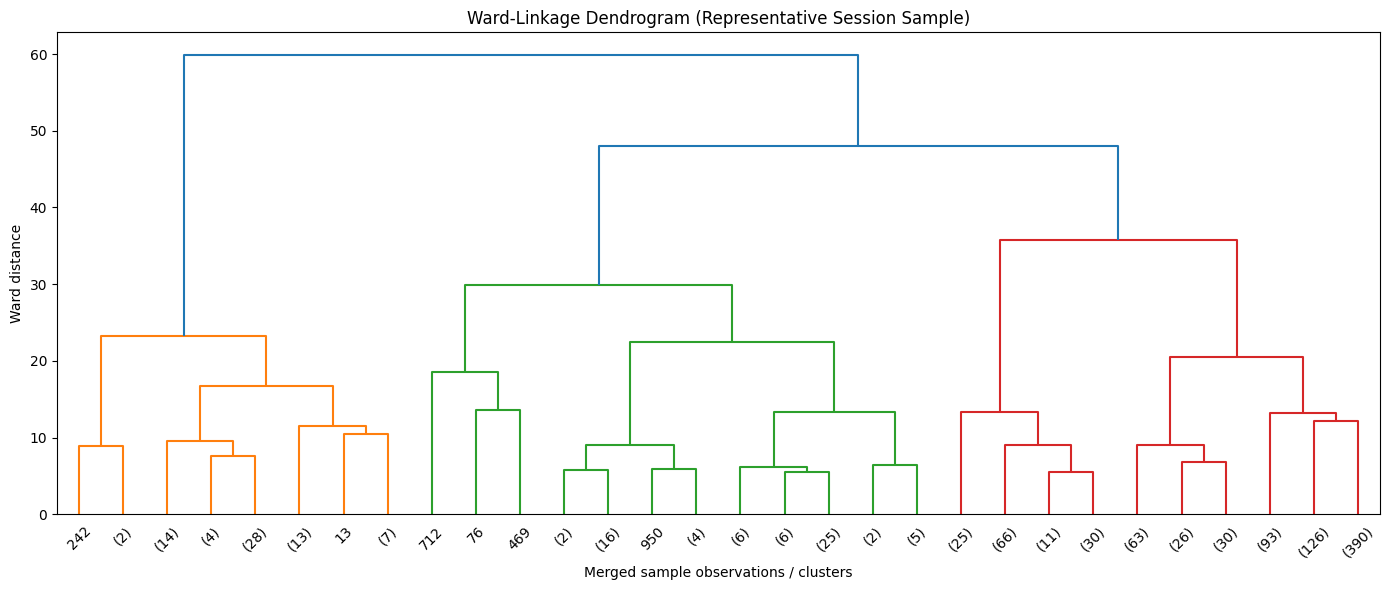

In [26]:
DENDROGRAM_SAMPLE_SIZE = min(1000, cluster_sample_size)
dendrogram_indices = rng.choice(
    cluster_sample_size,
    size=DENDROGRAM_SAMPLE_SIZE,
    replace=False
)
X_dendrogram = X_hierarchical[dendrogram_indices]
ward_linkage = linkage(X_dendrogram, method="ward")

plt.figure(figsize=(14, 6))
dendrogram(
    ward_linkage,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True
)
plt.title("Ward-Linkage Dendrogram (Representative Session Sample)")
plt.xlabel("Merged sample observations / clusters")
plt.ylabel("Ward distance")
plt.tight_layout()
plt.show()


### 5.8 Cluster Profiling and Sizes

**Purpose:** Reports means and medians for eligible labeled sessions, plus each cluster's size and proportion among those sessions. Means can be influenced by long-tailed counts, prices, and durations, so medians are shown alongside them. Cluster IDs are arbitrary. For a small cluster, compare its median behavioral profile and fitted-sample distance distribution with the other clusters: a distinct, reasonably compact profile is more consistent with a behavioral group, while an unusually diffuse group with no distinct profile may be outlier-driven. These are descriptive diagnostics, not a formal outlier test.

In [27]:
cluster_profile_mean = (
    session_features
    .groupby("cluster", observed=True)[cluster_features]
    .mean()
    .round(2)
)
cluster_profile_median = (
    session_features
    .groupby("cluster", observed=True)[cluster_features]
    .median()
    .round(2)
)
print("Cluster feature means:")
display(cluster_profile_mean)
print("Cluster feature medians:")
display(cluster_profile_median)

cluster_sizes = session_features["cluster"].value_counts().sort_index()
cluster_summary = cluster_sizes.rename("Sessions").to_frame()
cluster_summary["Percentage"] = (
    cluster_sizes.div(cluster_sizes.sum()).mul(100).round(2)
)
print("Cluster sizes among eligible labeled sessions:")
display(cluster_summary)

sample_distances = np.linalg.norm(
    X_hierarchical - cluster_centroids[sample_labels], axis=1
)
fit_sample_diagnostics = (
    pd.DataFrame({"cluster": sample_labels, "distance_to_sample_centroid": sample_distances})
    .groupby("cluster")["distance_to_sample_centroid"]
    .agg(sample_size="size", median_distance="median", p95_distance=lambda x: x.quantile(0.95))
    .round(3)
)
print("Exact fit-sample compactness diagnostics (not an outlier test):")
display(fit_sample_diagnostics)

Cluster feature means:


,unique_products_viewed,unique_categories_viewed,total_views,cart_additions,unique_products_carted,avg_price_viewed,session_duration_minutes
cluster,,,,,,,
0,2.26,1.19,3.19,0.00,0.00,315.94,12.87
1,2.65,1.22,5.30,1.58,1.10,346.45,10.92
2,15.02,3.91,22.45,0.03,0.02,243.62,32.00
3,2.35,1.22,7.79,0.03,0.02,316.08,22842.52


Cluster feature medians:


,unique_products_viewed,unique_categories_viewed,total_views,cart_additions,unique_products_carted,avg_price_viewed,session_duration_minutes
cluster,,,,,,,
0,1.0,1.0,2.0,0.0,0.0,185.00,0.68
1,2.0,1.0,3.0,1.0,1.0,223.02,3.73
2,13.0,4.0,19.0,0.0,0.0,175.43,16.70
3,1.0,1.0,5.0,0.0,0.0,220.85,20748.35


Cluster sizes among eligible labeled sessions:


,Sessions,Percentage
cluster,,
0,8156355,88.25
1,559558,6.05
2,525311,5.68
3,1429,0.02


Exact fit-sample compactness diagnostics (not an outlier test):


,sample_size,median_distance,p95_distance
cluster,,,
0,4411,0.850,2.839
1,303,1.504,4.801
2,285,2.727,8.335
3,1,0.000,0.000


### 5.9 PCA 2D Visualization

**Purpose:** Projects a reproducible sample of up to 50,000 eligible sessions into two principal components and color-codes cluster assignments. Circle markers show nearest-centroid assignments; x markers show the exact hierarchical fit sample. The projection is descriptive and does not independently validate clustering quality.

PCA explained variance ratio: [0.33629796 0.26852743]
Total explained variance: 0.6048253908666876


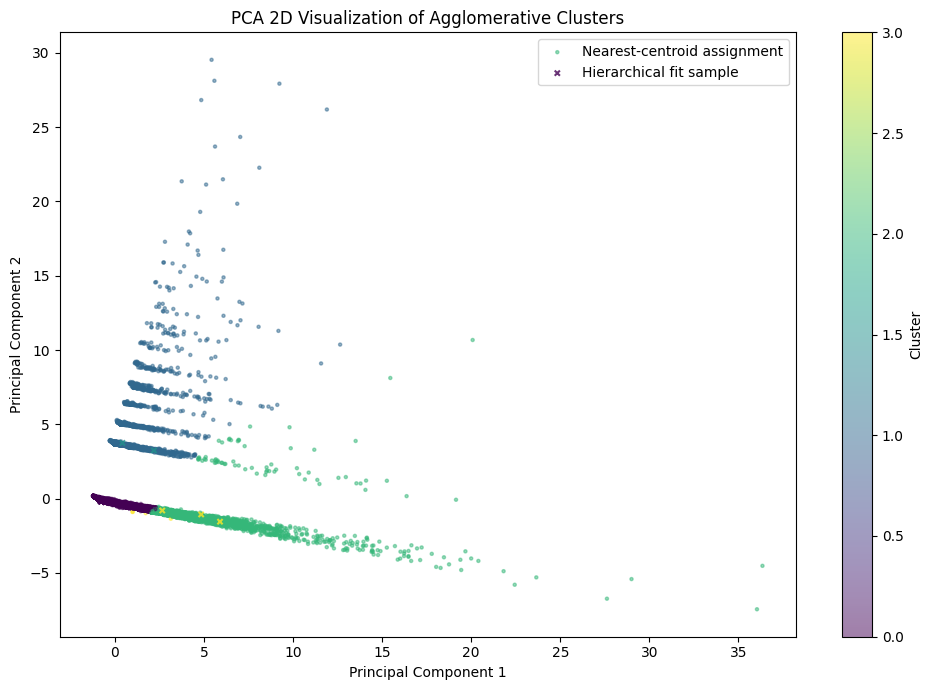

In [28]:
PCA_SAMPLE_SIZE = min(50000, n_eligible_sessions)
pca_indices = rng.choice(
    n_eligible_sessions,
    size=PCA_SAMPLE_SIZE,
    replace=False
)
X_pca_sample = scaler.transform(
    X_cluster.iloc[pca_indices].to_numpy(dtype=np.float64, copy=False)
)
labels_pca = cluster_labels[pca_indices]
fit_mask_pca = np.isin(pca_indices, cluster_sample_indices)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_pca_sample)
print("PCA explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    X_pca[~fit_mask_pca, 0],
    X_pca[~fit_mask_pca, 1],
    c=labels_pca[~fit_mask_pca],
    s=5,
    alpha=0.5,
    cmap="viridis",
    label="Nearest-centroid assignment"
)
plt.scatter(
    X_pca[fit_mask_pca, 0],
    X_pca[fit_mask_pca, 1],
    c=labels_pca[fit_mask_pca],
    s=14,
    alpha=0.8,
    cmap="viridis",
    marker="x",
    label="Hierarchical fit sample"
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA 2D Visualization of Agglomerative Clusters")
plt.colorbar(scatter, label="Cluster")
plt.legend()
plt.tight_layout()
plt.show()

### 5.10 t-SNE Visualization

**Purpose:** Projects up to 3,000 eligible sessions using a reproducible sample and color-codes assigned clusters. Circle markers identify nearest-centroid assignments; x markers identify the exact hierarchical fit sample. t-SNE emphasizes local neighborhoods, is sensitive to settings, and can visually separate groups even when clustering is not robust; use the metrics and profiles for evaluation.

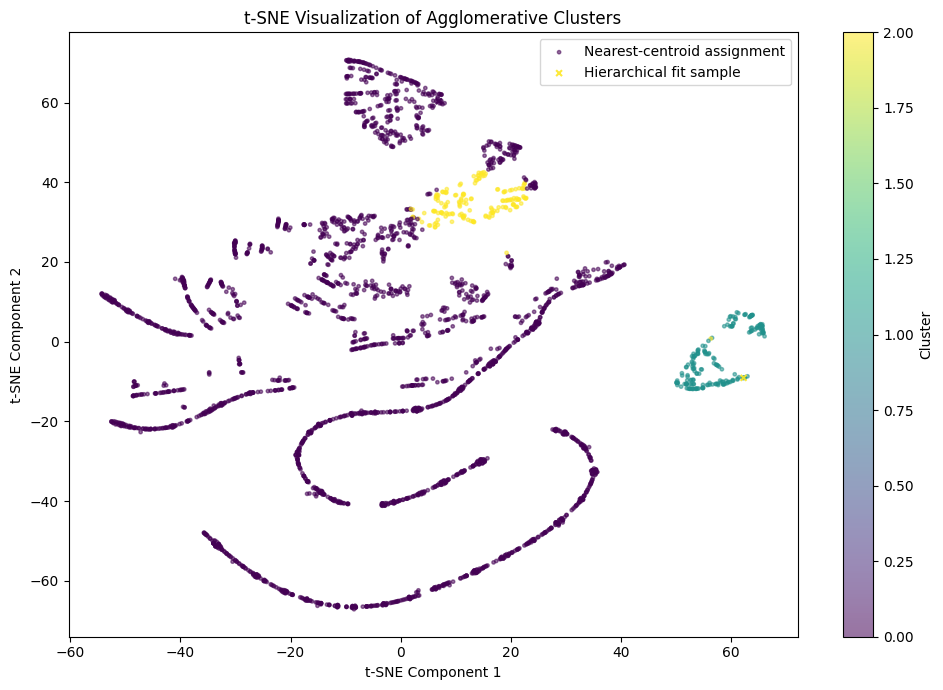

In [29]:
TSNE_SAMPLE_SIZE = min(3000, n_eligible_sessions)
tsne_indices = rng.choice(
    n_eligible_sessions,
    size=TSNE_SAMPLE_SIZE,
    replace=False
)
X_tsne_sample = scaler.transform(
    X_cluster.iloc[tsne_indices].to_numpy(dtype=np.float64, copy=False)
)
labels_tsne = cluster_labels[tsne_indices]
fit_mask_tsne = np.isin(tsne_indices, cluster_sample_indices)

if TSNE_SAMPLE_SIZE <= 30:
    raise ValueError(
        "t-SNE requires more rows than its perplexity; at least 31 eligible sessions are needed."
    )

tsne = TSNE(
    n_components=2,
    random_state=RANDOM_STATE,
    perplexity=30,
    max_iter=1000,
    init="pca",
    learning_rate="auto",
    n_jobs=1
)
X_tsne = tsne.fit_transform(X_tsne_sample)

plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    X_tsne[~fit_mask_tsne, 0],
    X_tsne[~fit_mask_tsne, 1],
    c=labels_tsne[~fit_mask_tsne],
    s=6,
    alpha=0.55,
    cmap="viridis",
    label="Nearest-centroid assignment"
)
plt.scatter(
    X_tsne[fit_mask_tsne, 0],
    X_tsne[fit_mask_tsne, 1],
    c=labels_tsne[fit_mask_tsne],
    s=18,
    alpha=0.9,
    cmap="viridis",
    marker="x",
    label="Hierarchical fit sample"
)
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.title("t-SNE Visualization of Agglomerative Clusters")
plt.colorbar(scatter, label="Cluster")
plt.legend()
plt.tight_layout()
plt.show()

### 6. Export Artifacts for Streamlit Dashboard

**Purpose:** Saves all clustering results, profiles, metrics, and visualizations needed by `app.py` without requiring the full pipeline to re-run on every dashboard visit. Artifacts are written to `models/agg_clustering_artifacts/` relative to the project root.

**Exported artifacts:**
- Fitted `StandardScaler` (7 features)
- Cluster centroids in the scaled feature space
- Cluster mean and median profiles
- Cluster summary (session counts and percentages)
- Evaluation metrics for the configured K=4 model
- Evaluation results for K=2 through K=6
- Feature column names and model configuration
- Dendrogram, PCA, and t-SNE images

In [30]:
# ─────────────────── Export Artifacts for Streamlit Dashboard ───────────────────
import joblib
from pathlib import Path

# Resolve the project root reliably (notebook lives in notebooks/)
_nb_dir = Path.cwd()
if _nb_dir.name == "notebooks":
    _project_root = _nb_dir.parent
else:
    _project_root = _nb_dir

AGG_ARTIFACTS_DIR = _project_root / "models" / "agg_clustering_artifacts"
AGG_ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

# 1. Scaler
joblib.dump(scaler, AGG_ARTIFACTS_DIR / "agg_scaler.pkl")

# 2. Cluster centroids (computed from fitted sample in scaled space)
joblib.dump(cluster_centroids, AGG_ARTIFACTS_DIR / "agg_centroids.npy")

# 3. Cluster profiles (mean and median)
joblib.dump(cluster_profile_mean, AGG_ARTIFACTS_DIR / "agg_profile_mean.pkl")
joblib.dump(cluster_profile_median, AGG_ARTIFACTS_DIR / "agg_profile_median.pkl")

# 4. Cluster summary (sizes and percentages)
joblib.dump(cluster_summary, AGG_ARTIFACTS_DIR / "agg_cluster_summary.pkl")

# 5. Configured model evaluation metrics (K=4, fitted 5000 sample)
joblib.dump(evaluation_results, AGG_ARTIFACTS_DIR / "agg_eval_metrics.pkl")

# 6. Multi-K evaluation table
joblib.dump(evaluation_by_k, AGG_ARTIFACTS_DIR / "agg_eval_by_k.pkl")

# 7. Feature list and model config
agg_config = {
    "cluster_features": cluster_features,
    "n_clusters": N_CLUSTERS,
    "linkage": "ward",
    "hierarchical_sample_size": cluster_sample_size,
    "n_eligible_sessions": n_eligible_sessions,
    "k_selection_sample_size": K_SELECTION_SAMPLE_SIZE,
    "random_state": RANDOM_STATE,
}
joblib.dump(agg_config, AGG_ARTIFACTS_DIR / "agg_config.pkl")

# 8. Save visualizations as images
# 8a. Dendrogram
fig_dendro, ax_dendro = plt.subplots(figsize=(14, 6))
dendrogram(
    ward_linkage,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True,
    ax=ax_dendro
)
ax_dendro.set_title("Ward-Linkage Dendrogram (Representative Session Sample)")
ax_dendro.set_xlabel("Merged sample observations / clusters")
ax_dendro.set_ylabel("Ward distance")
fig_dendro.tight_layout()
fig_dendro.savefig(AGG_ARTIFACTS_DIR / "dendrogram.png", dpi=150, bbox_inches="tight")
plt.close(fig_dendro)

# 8b. PCA
fig_pca, ax_pca = plt.subplots(figsize=(10, 7))
scatter_pca = ax_pca.scatter(
    X_pca[~fit_mask_pca, 0], X_pca[~fit_mask_pca, 1],
    c=labels_pca[~fit_mask_pca], s=5, alpha=0.5, cmap="viridis",
    label="Nearest-centroid assignment"
)
ax_pca.scatter(
    X_pca[fit_mask_pca, 0], X_pca[fit_mask_pca, 1],
    c=labels_pca[fit_mask_pca], s=14, alpha=0.8, cmap="viridis",
    marker="x", label="Hierarchical fit sample"
)
ax_pca.set_xlabel("Principal Component 1")
ax_pca.set_ylabel("Principal Component 2")
ax_pca.set_title("PCA 2D Visualization of Agglomerative Clusters")
fig_pca.colorbar(scatter_pca, ax=ax_pca, label="Cluster")
ax_pca.legend()
fig_pca.tight_layout()
fig_pca.savefig(AGG_ARTIFACTS_DIR / "pca_clusters.png", dpi=150, bbox_inches="tight")
plt.close(fig_pca)

# 8c. t-SNE
fig_tsne, ax_tsne = plt.subplots(figsize=(10, 7))
scatter_tsne = ax_tsne.scatter(
    X_tsne[~fit_mask_tsne, 0], X_tsne[~fit_mask_tsne, 1],
    c=labels_tsne[~fit_mask_tsne], s=6, alpha=0.55, cmap="viridis",
    label="Nearest-centroid assignment"
)
ax_tsne.scatter(
    X_tsne[fit_mask_tsne, 0], X_tsne[fit_mask_tsne, 1],
    c=labels_tsne[fit_mask_tsne], s=18, alpha=0.9, cmap="viridis",
    marker="x", label="Hierarchical fit sample"
)
ax_tsne.set_xlabel("t-SNE Component 1")
ax_tsne.set_ylabel("t-SNE Component 2")
ax_tsne.set_title("t-SNE Visualization of Agglomerative Clusters")
fig_tsne.colorbar(scatter_tsne, ax=ax_tsne, label="Cluster")
ax_tsne.legend()
fig_tsne.tight_layout()
fig_tsne.savefig(AGG_ARTIFACTS_DIR / "tsne_clusters.png", dpi=150, bbox_inches="tight")
plt.close(fig_tsne)

print("All agglomerative clustering artifacts exported to:")
print(f"  {AGG_ARTIFACTS_DIR}")
print("Exported files:")
for f in sorted(AGG_ARTIFACTS_DIR.iterdir()):
    print(f"  {f.name} ({f.stat().st_size / 1024:.1f} KB)")


All agglomerative clustering artifacts exported to:
  c:\Users\muthu\OneDrive\Desktop\ML-Capstone-Project\models\agg_clustering_artifacts
Exported files:
  agg_centroids.npy (0.4 KB)
  agg_cluster_summary.pkl (1.6 KB)
  agg_config.pkl (0.3 KB)
  agg_eval_by_k.pkl (1.2 KB)
  agg_eval_metrics.pkl (0.1 KB)
  agg_profile_mean.pkl (2.0 KB)
  agg_profile_median.pkl (2.0 KB)
  agg_scaler.pkl (0.7 KB)
  dendrogram.png (66.8 KB)
  pca_clusters.png (125.5 KB)
  tsne_clusters.png (242.4 KB)
